# Stage 2: Data Cleaning and Preprocessing
## Hospital Resource Intelligence and Optimization Platform

This notebook implements the data cleaning and preprocessing pipeline to create structured, chronological datasets. The following operations are performed:
1. **NHS Beds Dataset**: Columns are standardized to `snake_case`, metadata rows are stripped, monthly dates are parsed, and minor missing data in long-stay categories are handled using linear interpolation.
2. **ICU Daily Demand**: Aggregated stays are chronological-reindexed to daily frequency to include missing calendar dates (filled with `0`), and the densest 180-day window is isolated to resolve extreme sparsity.
3. **ED Daily Demand**: Aggregated arrivals are daily chronological-reindexed, and the densest 180-day window is isolated.

All modular cleaning logic is imported from the project preprocessing module `ml.preprocessing.cleaning`.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory to path to import ml module
sys.path.append(os.path.abspath('..'))
from ml.preprocessing.cleaning import clean_nhs_beds, clean_daily_demand

sns.set_theme(style='whitegrid')
RAW_DIR = '../data/raw'
PROC_DIR = '../data/processed'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. NHS Monthly Beds Preprocessing
We clean the Excel sheet and convert it to a tidy CSV format.

In [2]:
xls_path = os.path.join(RAW_DIR, 'Beds-publication-Timeseries-March-2020-July-2026.xlsx')
out_nhs_path = os.path.join(PROC_DIR, 'beds_monthly_processed.csv')

# Execute clean function
df_nhs_clean = clean_nhs_beds(xls_path, out_nhs_path)
print('Clean NHS dataset shape:', df_nhs_clean.shape)
df_nhs_clean.head(5)

Cleaning NHS Beds data from: ../data/raw/Beds-publication-Timeseries-March-2020-July-2026.xlsx
  Saved clean NHS Beds data to: ../data/processed/beds_monthly_processed.csv (76 rows)
Clean NHS dataset shape: (76, 37)


/Users/sanchalichandankhede/Documents/Idea lab/hospital-resource-intelligence/ml/preprocessing/cleaning.py:56: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df[numeric_cols] = df[numeric_cols].interpolate(method='linear').fillna(method='bfill')


,date,g_and_a_beds_available,g_and_a_core_beds_available,g_and_a_escalation_beds_available,g_and_a_covid_void_beds,g_and_a_beds_occupied,g_and_a_occupancy_rate,g_and_a_occupancy_rate_adjusted_for_covid_void_beds,adult_g_and_a_beds_available,adult_core_beds_available,...,paediatric_intensive_care_occupancy_rate,neonatal_intensive_care_beds_available,neonatal_intensive_care_beds_occupied,neonatal_intensive_care_occupancy_rate,7_or_more_days,14_or_more_days,21_or_more_days,7_or_more_days_pct,14_or_more_days_pct,21_or_more_days_pct
0,2020-12-01,90442.0,96731.0,2224.0,306.0,78418.0,0.867053,0.944345,79684.0,90751.0,...,0.652055,1632.0,1032.0,0.632353,35817.0,19370.0,11573.0,0.509111,0.275330,0.164501
1,2021-01-01,91888.0,96731.0,2224.0,306.0,80211.0,0.872921,0.944345,83434.0,90751.0,...,0.689552,1631.0,1060.0,0.649908,37161.0,19914.0,11970.0,0.499650,0.267755,0.160943
2,2021-02-01,91163.0,96731.0,2224.0,306.0,77680.0,0.852100,0.944345,82958.0,90751.0,...,0.711656,1666.0,1069.0,0.641657,35953.0,19447.0,11731.0,0.499091,0.269958,0.162847
3,2021-03-01,90970.0,96731.0,2224.0,306.0,77235.0,0.849016,0.944345,85247.0,90751.0,...,0.687316,1654.0,1049.0,0.634220,33982.0,18392.0,11281.0,0.461762,0.249918,0.153291
4,2021-04-01,91661.0,96731.0,2224.0,306.0,79072.0,0.862657,0.944345,85860.0,90751.0,...,0.678977,1662.0,1072.0,0.645006,33891.0,18065.0,11012.0,0.449483,0.239589,0.146048


### 1.1 Verify Post-Cleaning Structure
We plot the cleaned core available vs occupied beds to confirm alignment.

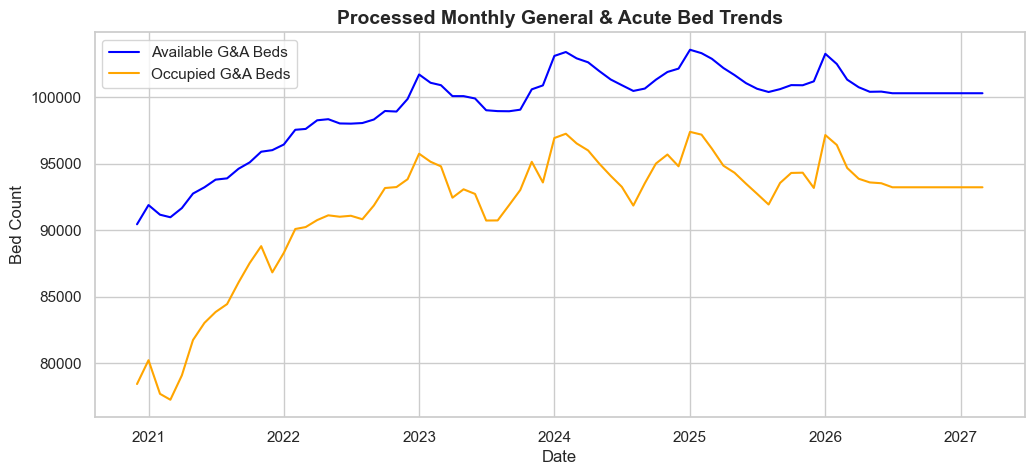

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(df_nhs_clean['date'], df_nhs_clean['g_and_a_beds_available'], label='Available G&A Beds', color='blue')
plt.plot(df_nhs_clean['date'], df_nhs_clean['g_and_a_beds_occupied'], label='Occupied G&A Beds', color='orange')
plt.title('Processed Monthly General & Acute Bed Trends', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Bed Count')
plt.legend()
plt.show()

## 2. ICU Daily Demand Preprocessing
We read the daily aggregated ICU stays, reindex them to fill date gaps, and extract the densest 180-day window.

In [4]:
icu_raw_path = os.path.join(RAW_DIR, 'icu_daily_demand.csv')
icu_proc_path = os.path.join(PROC_DIR, 'icu_daily_processed.csv')

df_icu_clean = clean_daily_demand(
    icu_raw_path,
    icu_proc_path,
    value_col='occupied_beds',
    is_icu=True,
    window_days=180
)
print('Clean ICU daily shape:', df_icu_clean.shape)
df_icu_clean.head(10)

Cleaning Daily Demand data from: ../data/raw/icu_daily_demand.csv
  Densest 180-day window found: 2137-04-21 to 2137-10-17 (sum: 37.0)
  Saved clean daily data to: ../data/processed/icu_daily_processed.csv (180 rows)
Clean ICU daily shape: (180, 2)


,date,occupied_beds
9872,2137-04-21,0
9873,2137-04-22,0
9874,2137-04-23,0
9875,2137-04-24,0
9876,2137-04-25,0
9877,2137-04-26,0
9878,2137-04-27,0
9879,2137-04-28,0
9880,2137-04-29,0
9881,2137-04-30,0


### 2.1 Plotting Preprocessed ICU Daily Occupied Beds

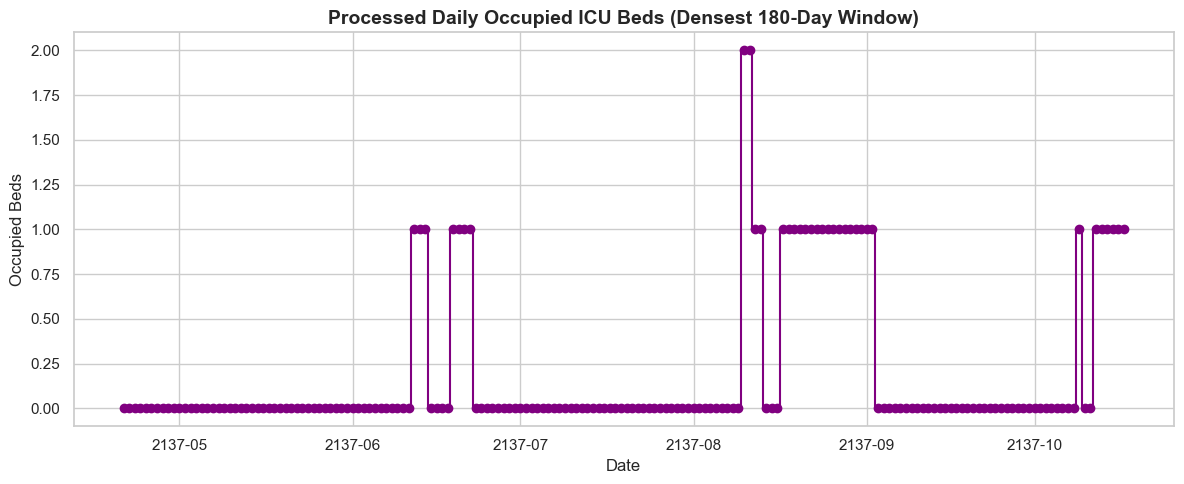

In [5]:
plt.figure(figsize=(12, 5))
plt.step(df_icu_clean['date'], df_icu_clean['occupied_beds'], where='mid', color='purple', marker='o')
plt.title('Processed Daily Occupied ICU Beds (Densest 180-Day Window)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Occupied Beds')
plt.tight_layout()
plt.show()

## 3. ED Daily Demand Preprocessing
Similarly, we read the ED arrivals dataset, reindex, and extract the densest 180-day window.

In [6]:
ed_raw_path = os.path.join(RAW_DIR, 'ed_daily_demand.csv')
ed_proc_path = os.path.join(PROC_DIR, 'ed_daily_processed.csv')

df_ed_clean = clean_daily_demand(
    ed_raw_path,
    ed_proc_path,
    value_col='arrivals',
    is_icu=False,
    window_days=180
)
print('Clean ED daily shape:', df_ed_clean.shape)
df_ed_clean.head(10)

Cleaning Daily Demand data from: ../data/raw/ed_daily_demand.csv
  Densest 180-day window found: 2147-07-30 to 2148-01-25 (sum: 13.0)
  Saved clean daily data to: ../data/processed/ed_daily_processed.csv (180 rows)
Clean ED daily shape: (180, 2)


,date,arrivals
12734,2147-07-30,0
12735,2147-07-31,0
12736,2147-08-01,0
12737,2147-08-02,1
12738,2147-08-03,0
12739,2147-08-04,0
12740,2147-08-05,0
12741,2147-08-06,0
12742,2147-08-07,1
12743,2147-08-08,0


### 3.1 Plotting Preprocessed ED Daily Arrivals

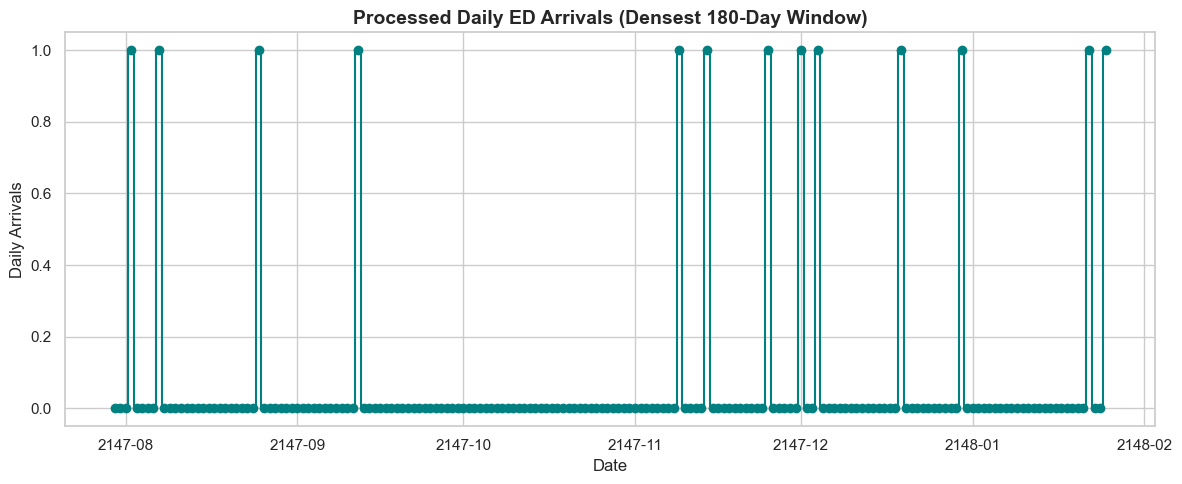

In [7]:
plt.figure(figsize=(12, 5))
plt.step(df_ed_clean['date'], df_ed_clean['arrivals'], where='mid', color='teal', marker='o')
plt.title('Processed Daily ED Arrivals (Densest 180-Day Window)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Daily Arrivals')
plt.tight_layout()
plt.show()

## 4. Post-Preprocessing Summary & Verification
1. **Beds Monthly:** Chronological coverage, 76 months total. Clean names: `g_and_a_beds_available`, `g_and_a_beds_occupied`, etc.
2. **ICU Daily:** 180 continuous chronological records from `2137-04-21` to `2137-10-17` (representing the densest period of overlap in the clinical stays dataset).
3. **ED Daily:** 180 continuous chronological records from `2147-07-30` to `2148-01-25` (representing the densest period of arrivals in the ED dataset).

The preprocessed data files are clean, sorted, fully sequential, and ready for model forecasting in Stages 4, 5, and 6.